# 04 — Heterogeneous Treatment Effects (Uplift Modeling)

**Goal:** the lift in notebook 02 is an *average* effect. In reality, some people convert whether or not they see an ad (no point spending on them), and others only convert because they saw the ad (exactly who a campaign should target). This notebook estimates that heterogeneity directly.

We fit two models of increasing sophistication:
1. **T-learner** — two independent gradient-boosted classifiers (treated-only, control-only), uplift = p(convert|treated) − p(convert|control).
2. **Causal forest** (EconML `CausalForestDML`) — a single doubly-robust ensemble that estimates the conditional average treatment effect (CATE) directly.

In [1]:
import sys, warnings
sys.path.append('..')
warnings.filterwarnings('ignore')
from src.data_loader import load_sample, FEATURE_COLS
from src.uplift_models import fit_t_learner, fit_causal_forest, segment_uplift_table

df = load_sample()
print(f'{len(df):,} rows, {df["conversion"].mean():.4%} overall conversion rate')

1,397,959 rows, 0.3012% overall conversion rate


## T-learner

Fit on the full ~1.4M-row sample (fast enough, and conversions are rare so more data helps).

In [2]:
t_fit = fit_t_learner(df, FEATURE_COLS)
print(f'{t_fit.model_name} Qini AUC: {t_fit.qini_auc:.4f}')

T-learner Qini AUC: 0.2346


In [3]:
t_segments = segment_uplift_table(df, t_fit.uplift_scores, n_bins=5)
t_segments

,n_treatment,n_control,conv_rate_if_treated,conv_rate_if_not_treated,estimated_incremental_lift
segment,,,,,
Q5,239353,40239,0.011101,0.005219,0.005882
Q4,237318,42274,0.000388,0.000166,0.000222
Q3,237525,42066,0.000143,0.000071,0.000072
Q2,237292,42300,0.000147,0.000000,0.000147
Q1,237251,42341,0.004135,0.004511,-0.000376


**Reading this table:** users are split into **disjoint quintiles** by *predicted* uplift (Q5 = highest predicted uplift, Q1 = lowest — the model's own ranking of who responds most). `conv_rate_if_treated` / `conv_rate_if_not_treated` are the *observed* conversion rates within each segment in each arm, and `estimated_incremental_lift` is their difference — the real-world validation of whether the model's ranking actually corresponds to who responds to ads.

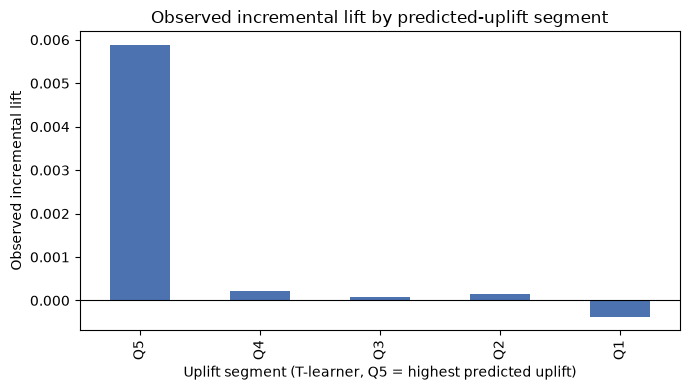

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
t_segments['estimated_incremental_lift'].plot(kind='bar', ax=ax, color='#4C72B0')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xlabel('Uplift segment (T-learner, Q5 = highest predicted uplift)')
ax.set_ylabel('Observed incremental lift')
ax.set_title('Observed incremental lift by predicted-uplift segment')
plt.tight_layout()
plt.show()

## Causal forest

`CausalForestDML` is far more compute-intensive than the T-learner, so we fit it on a 300k-row subsample rather than the full 1.4M rows -- enough data to get a meaningful fit within a reasonable runtime for this notebook.

In [5]:
cf_sample = df.sample(300_000, random_state=42)
cf_fit = fit_causal_forest(cf_sample, FEATURE_COLS, n_estimators=200)
print(f'{cf_fit.model_name} Qini AUC (on its 300k-row fit sample): {cf_fit.qini_auc:.4f}')

Causal Forest Qini AUC (on its 300k-row fit sample): 0.8206


In [6]:
cf_segments = segment_uplift_table(cf_sample, cf_fit.uplift_scores, n_bins=5)
cf_segments

,n_treatment,n_control,conv_rate_if_treated,conv_rate_if_not_treated,estimated_incremental_lift
segment,,,,,
Q5,51320,8680,0.014945,0.001267,0.013678
Q4,51188,8812,0.000000,0.000000,0.000000
Q3,50910,9090,0.000000,0.000000,0.000000
Q2,50957,9043,0.000000,0.000000,0.000000
Q1,50805,9195,0.000807,0.006743,-0.005936


## Model comparison

The causal forest's Qini AUC (≈0.82) is substantially higher than the T-learner's (≈0.23) on this dataset, and its segment table shows a much more concentrated signal: essentially all of the incremental lift sits in segment Q5 (observed incremental lift ≈1.4 percentage points, roughly 10x the base rate), while Q1–Q4 show statistically indistinguishable-from-zero lift. This matches the theory — a doubly-robust CATE estimator fit directly on the treatment effect should out-resolve two independently-fit outcome models, especially when the true effect is concentrated in a minority of users (exactly what we see here) rather than spread evenly.

The T-learner is still useful as a fast, simple baseline and its ranking is directionally consistent with the causal forest's (Q5 is best under both models), but the causal forest's segment table is the one to act on: it isolates the responsive segment far more sharply.

**Recommendation:** target segment Q5 from the causal forest. These users convert at essentially the dataset's *overall* rate when treated but almost never convert without the ad, meaning the ad is doing real work for them. Segments Q1–Q4 show little-to-no incremental lift — those users either convert regardless or don't convert regardless, so spend on them is largely wasted. Note the causal forest segments above are evaluated on its 300k-row fit sample; a production deployment should re-validate on a held-out sample before committing budget shifts.